In [122]:
print("Hello! My first Machine Learning project.")
print("Python is working successfully!")

Hello! My first Machine Learning project.
Python is working successfully!


In [123]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [124]:
# Load the California Housing dataset
data = fetch_california_housing(as_frame=True)

# Combine the features and house price target
df = pd.concat(
    [data.data, data.target.rename("MedHouseVal")],
    axis=1
)

# Display dataset information
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

# Display first 5 rows
df.head()

Dataset loaded successfully!
Dataset shape: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [125]:
# Dataset information
print("Dataset Information:")
df.info()

# Statistical summary
print("\nStatistical Summary:")
display(df.describe())

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:")
print(df.duplicated().sum())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB

Statistical Summary:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010



Missing Values:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

Duplicate Records:
0


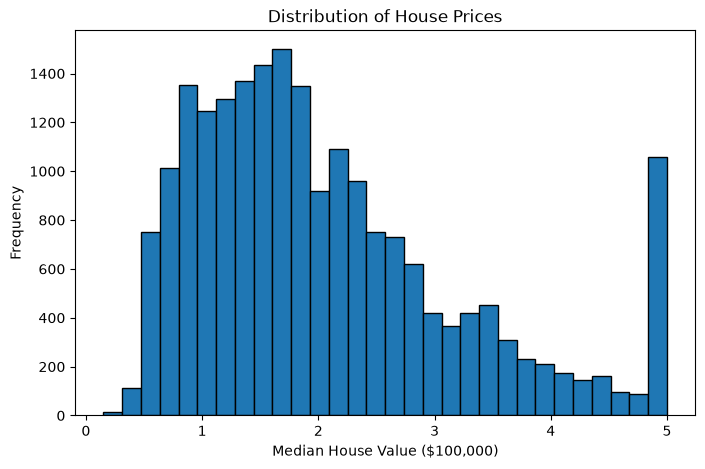

In [126]:
plt.figure(figsize=(8, 5))

plt.hist(df["MedHouseVal"], bins=30, edgecolor="black")

plt.xlabel("Median House Value ($100,000)")
plt.ylabel("Frequency")
plt.title("Distribution of House Prices")

plt.show()

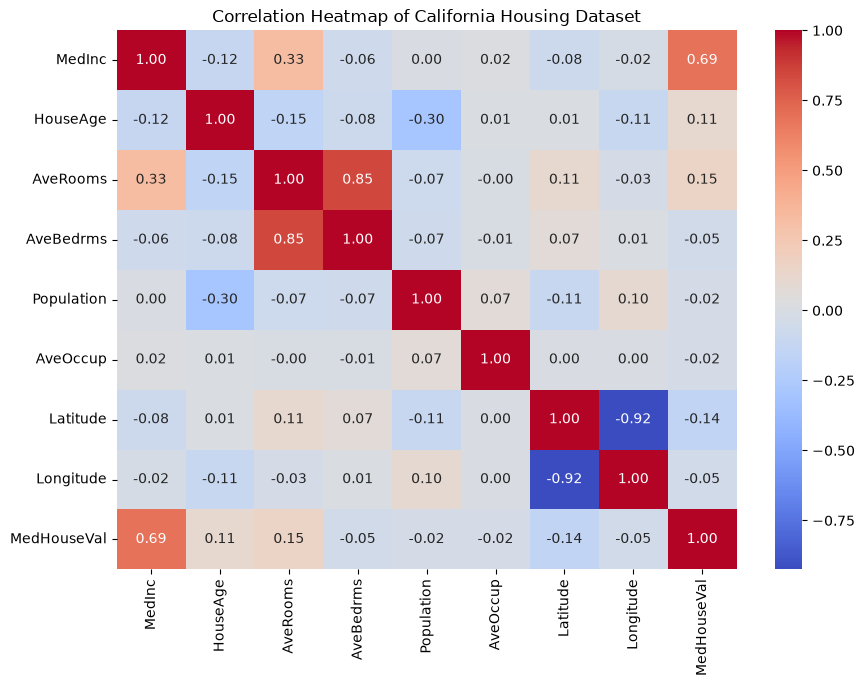

In [127]:
plt.figure(figsize=(10, 7))

correlation = df.corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of California Housing Dataset")
plt.show()

In [128]:
# Select input features (X) and target variable (y)

X = df.drop(columns="MedHouseVal")
y = df["MedHouseVal"]

print("Features:", X.columns.tolist())
print("Target:", "MedHouseVal")
print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
Target: MedHouseVal
Feature shape: (20640, 8)
Target shape: (20640,)


In [129]:
# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 16512
Testing records: 4128


In [130]:
# Create Linear Regression model

model = LinearRegression()

# Train the model using training data

model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [131]:
# Predict house prices using test data

y_pred = model.predict(X_test)

print("Predictions generated successfully!")

# Compare actual and predicted values

results = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

display(results.head(10))

Predictions generated successfully!


,Actual Price,Predicted Price
0,0.47700,0.719123
1,0.45800,1.764017
2,5.00001,2.709659
3,2.18600,2.838926
4,2.78000,2.604657
5,1.58700,2.011754
6,1.98200,2.645500
7,1.57500,2.168755
8,3.40000,2.740746
9,4.46600,3.915615


In [132]:

# Step 23: Model Evaluation

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Model Evaluation")
print("-------------------------")
print(f"MAE:  {mae:.3f}")
print(f"RMSE: {rmse:.3f}")
print(f"R²:   {r2:.3f}")


Model Evaluation
-------------------------
MAE:  0.533
RMSE: 0.746
R²:   0.576


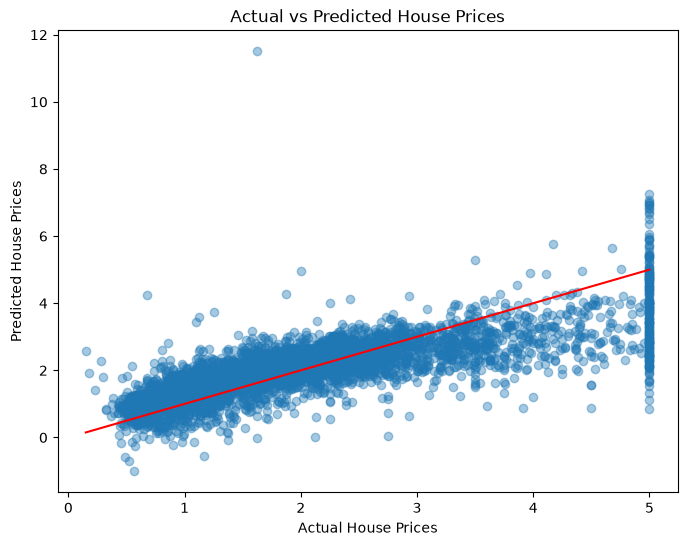

In [133]:

# Step 24: Actual vs Predicted House Prices

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.4)

plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")
plt.title("Actual vs Predicted House Prices")

# Perfect prediction reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red"
)

plt.show()


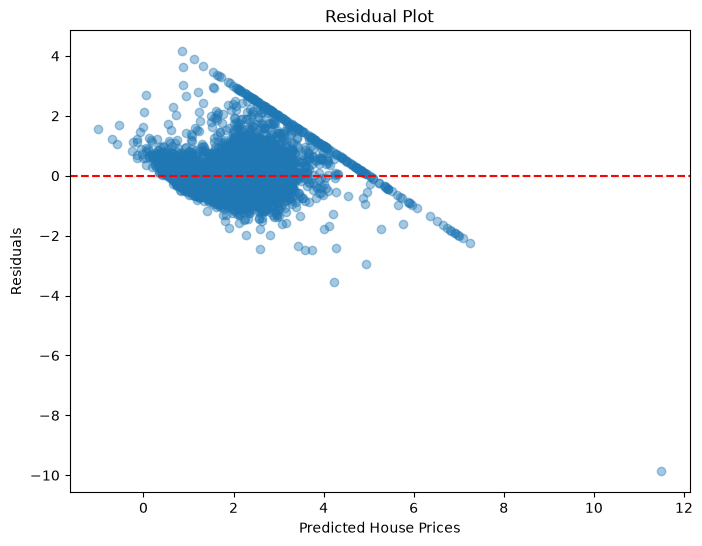

In [134]:

# Step 25: Calculate residuals

residuals = y_test - y_pred

plt.figure(figsize=(8, 6))

plt.scatter(y_pred, residuals, alpha=0.4)
plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted House Prices")
plt.ylabel("Residuals")
plt.title("Residual Plot")

plt.show()


In [135]:
import joblib

joblib.dump(model, "house_price_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [136]:
import os
import joblib

# Check whether the model file exists
print("Model file exists:", os.path.exists("house_price_model.pkl"))

# Load the saved model
loaded_model = joblib.load("house_price_model.pkl")

print("Saved model loaded successfully!")

Model file exists: True
Saved model loaded successfully!


## Model Evaluation and Performance

The Linear Regression model was evaluated using three performance metrics.

| Evaluation Metric | Result |
|---|---:|
| Mean Absolute Error (MAE) | 0.533 |
| Root Mean Squared Error (RMSE) | 0.746 |
| R-squared (R²) | 0.576 |

### Interpretation

- MAE of 0.533 indicates the average absolute prediction error.
- RMSE of 0.746 indicates the overall prediction error, with larger errors receiving greater weight.
- R² of 0.576 indicates that the model explains 57.6% of the variation in median house values.

### Conclusion

The Linear Regression model successfully predicted median house values using eight input features. The model achieved an R² score of 0.576. Further improvements may be possible through feature engineering and testing other machine learning algorithms.